In [ ]:
!pip install cryptography pycryptodome scikit-learn xgboost pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 49.7 MB/s eta 0:00:00


In [ ]:
from cryptography.hazmat.primitives.asymmetric import ec
from cryptography.hazmat.primitives import serialization

# Generate keys for User
user_private = ec.generate_private_key(ec.SECP256R1())
user_public = user_private.public_key()
print("user keys generated ")

# Generate keys for Cloud/Doctor
server_private = ec.generate_private_key(ec.SECP256R1())
server_public = server_private.public_key()
print("server keys generated ")


# Shared key (ECDH)
shared_key_user = user_private.exchange(ec.ECDH(), server_public)
shared_key_server = server_private.exchange(ec.ECDH(), user_public)

print("Shared keys match:", shared_key_user == shared_key_server)

user keys generated 
server keys generated 
Shared keys match: True


In [ ]:
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes

def derive_aes_key(shared_key):
    return HKDF(
        algorithm=hashes.SHA256(),
        length=32,  # AES-256
        salt=None,
        info=b'handshake data'
    ).derive(shared_key)

aes_key = derive_aes_key(shared_key_user)

In [ ]:
from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

def encrypt(data, key):
    cipher = AES.new(key, AES.MODE_GCM)
    ciphertext, tag = cipher.encrypt_and_digest(data.encode())
    return cipher.nonce, ciphertext, tag

def decrypt(nonce, ciphertext, tag, key):
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    return cipher.decrypt_and_verify(ciphertext, tag).decode()

# Test
nonce, ct, tag = encrypt("Patient Depression Score: 0.82", aes_key)
print(decrypt(nonce, ct, tag, aes_key))

Patient Depression Score: 0.82


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
# Convert target
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

# Drop useless columns
df = df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1)

# Encode categorical variables
df = pd.get_dummies(df, drop_first=True)

# Split X and y
X = df.drop('Attrition', axis=1)
y = df['Attrition']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)

(1176, 44)


In [ ]:
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

mlp = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300)
mlp.fit(X_train, y_train)

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [08:15:17] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score

mlp_pred = mlp.predict_proba(X_test)[:, 1]
xgb_pred = xgb.predict_proba(X_test)[:, 1]

final_pred = (mlp_pred + xgb_pred) / 2
final_pred = (final_pred > 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, final_pred))

Accuracy: 0.8503401360544217


In [ ]:
risk_score = str(final_pred[0])  # Example output

nonce, ct, tag = encrypt(risk_score, aes_key)

# Store in cloud (simulated)
cloud_storage = {
    "nonce": nonce,
    "ciphertext": ct,
    "tag": tag
}

In [ ]:
def user_send_data(data):
    nonce, ct, tag = encrypt(data, aes_key)
    return {"nonce": nonce, "ciphertext": ct, "tag": tag}

In [ ]:
def doctor_view_data(enc_data):
    return decrypt(enc_data["nonce"], enc_data["ciphertext"], enc_data["tag"], aes_key)

In [ ]:
cloud_db = []

def store_in_cloud(data):
    cloud_db.append(data)

def retrieve_from_cloud(index):
    return cloud_db[index]

In [ ]:
import time

start = time.time()
nonce, ct, tag = encrypt("test data", aes_key)
enc_time = (time.time() - start) * 1000

start = time.time()
decrypt(nonce, ct, tag, aes_key)
dec_time = (time.time() - start) * 1000

print("Encryption time:", enc_time, "ms")
print("Decryption time:", dec_time, "ms")

Encryption time: 2.5038719177246094 ms
Decryption time: 0.4782676696777344 ms


In [ ]:
key = get_random_bytes(32)

start = time.time()
cipher = AES.new(key, AES.MODE_GCM)
cipher.encrypt(b"test")
print("AES only:", (time.time() - start)*1000)

AES only: 0.4420280456542969


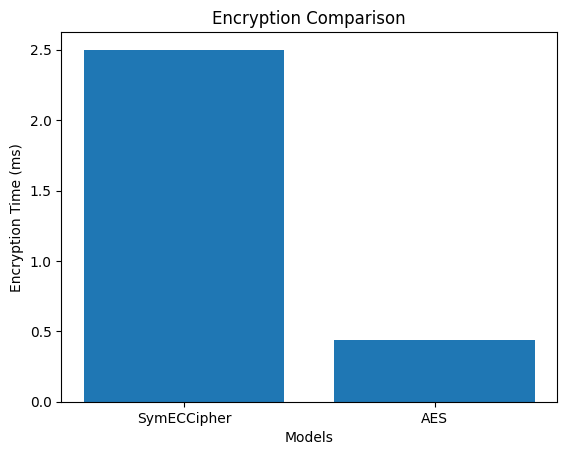

In [ ]:
import matplotlib.pyplot as plt

models = ["SymECCipher", "AES"]
enc_times = [2.5, 0.44]

plt.bar(models, enc_times)
plt.xlabel("Models")
plt.ylabel("Encryption Time (ms)")
plt.title("Encryption Comparison")
plt.show()